# Bayesian Optimisation for Membrane / CHOL values — Yield & Duplicate Discrepancy

Same three surrogate models as in `BO_Bioreactor_v2.ipynb`:
- **ModelListGP**: two independent GPs (one per output), standard BoTorch baseline
- **MTGP**: `MultiTaskGP` (ICM coregionalization) — captures output correlation
- **RandomForest**: sklearn RF wrapped as a BoTorch-compatible model using tree-ensemble variance as proxy uncertainty

Each model runs **batch BO** ($q=3$) via `qLogNEHVI` (for GPs) and a Pareto-spread selection for the RF.

**Inputs**: `thickness`, `density`, `porosity`, `CHOL_input`
**Outputs**: `yield` (maximize), `duplicates_MAE` (minimize)

`duplicates_MAE` measures how reproducible a material / CHOL condition is: it is the mean absolute
difference between the product-concentration time series of two duplicate bioreactors over the 3
sampling times of each CHOL phase (computed in `MaterialsDatasetAnalysis.ipynb`). Lower is better.

**What changes with respect to v2**
1. The discrepancy is modelled as $z = -\log(\mathrm{MAE})$ (Section 2.1), so that both objectives
   are maximised and the model works on a scale where the discrepancy is well behaved.
2. `yield` keeps its reported SD as known noise. `duplicates_MAE` has **no reported SD**, so its noise
   is estimated from the raw duplicate time series (Section 2.2) and then passed to all three models
   exactly like the yield noise.
3. Plots and tables report the discrepancy back in its original units.

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.ensemble import RandomForestRegressor
from sklearn.utils import shuffle
from sklearn.utils import check_random_state

# BoTorch / GPyTorch
import botorch
import gpytorch
from botorch.models import ModelListGP, MultiTaskGP, SingleTaskGP
from botorch.models.model import Model
from botorch.fit import fit_gpytorch_mll
from botorch.utils.transforms import normalize, unnormalize
from botorch.utils.sampling import manual_seed
from botorch.acquisition.multi_objective.logei import qLogNoisyExpectedHypervolumeImprovement, qLogExpectedHypervolumeImprovement
from botorch.optim import optimize_acqf
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.posteriors import Posterior
from botorch.utils.multi_objective.pareto import is_non_dominated
from gpytorch.mlls import ExactMarginalLogLikelihood, SumMarginalLogLikelihood
from torch import Tensor

RSEED = 42
torch.manual_seed(RSEED)
np.random.seed(RSEED)
dtype = torch.double

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
print("Main Packages versions used: ")
print(f"PyTorch version     :  {torch.__version__}")
print(f"BoTorch version     :  {botorch.__version__}")
print(f"GPytorch version    :  {gpytorch.__version__}")

Main Packages versions used: 
PyTorch version     :  2.14.1+cu130
BoTorch version     :  0.17.2
GPytorch version    :  1.15.2


# 0. Bayesian Loop stages
This notebook uses every material currently in the dataset, i.e. the data of the second loop:
Poplar, Kapok, Milkweed, Viscose, Porous PET and Fluffy PET.

## 1. Load & Inspect Data

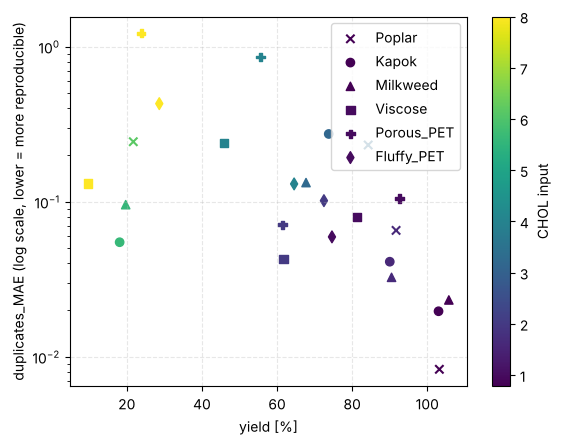

In [3]:
#---------------------------------------
# Load datasets
#---------------------------------------

full_inputs_df = pd.read_excel("Materials Dataset.xlsx", sheet_name="Inputs")
full_outputs_df = pd.read_excel("Materials Dataset.xlsx", sheet_name="Outputs")

#-----------------------------------------------
# Visualize outputs
#-----------------------------------------------

# Select inputs
inputs_df = full_inputs_df.drop(['moisture_abs'], axis=1)

# Select outputs (the discrepancy has no reported SD, see Section 2.2)
output_1 = 'yield'
output_2 = 'duplicates_MAE'
outputs_df = full_outputs_df[[output_1, output_1 + '_SD', output_2]]

# Set marker for different materials
material_shapes = {'Poplar': 'x', 'Kapok': 'o', 'Milkweed': '^', 'Viscose': 's',
                   'Porous_PET': 'P', 'Fluffy_PET': 'd'}

# Set up CHOL values for the colorbar
chol = full_inputs_df['CHOL_input']
norm = mpl.colors.Normalize(vmin = chol.min(), vmax = chol.max())
cmap = plt.cm.viridis

fig, ax = plt.subplots()

# Plot each material separately
for material, mark in material_shapes.items():
    mask = full_inputs_df['material'] == material

    ax.scatter(
        outputs_df.loc[mask, output_1],
        outputs_df.loc[mask, output_2],
        c=chol.loc[mask],
        cmap=cmap,
        norm=norm,
        label=material,
        marker=mark
    )

# Add colorbar
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('CHOL input')

ax.set_yscale('log')
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlabel(output_1 + ' [%]')
ax.set_ylabel(output_2 + ' (log scale, lower = more reproducible)')
ax.legend()

plt.show()

### Checking the discrepancy against the raw duplicates

`duplicates_MAE` was computed by splitting each duplicate time series into 4 consecutive groups of 3
sampling times, one group per CHOL phase. Before using it as an objective, check that group $k$ really
is the $k$-th CHOL value of each material: the mean concentration of each group must reproduce
`product_conc` from the dataset. The same groups are used in Section 2.2 to estimate how uncertain each
MAE value is: `MAE_SE` is the standard error of the mean of the 3 absolute differences.

In [4]:
duplicates_df = pd.read_excel("ProductConcentrationDuplicates.xlsx", header=1)

dup_columns = {'Poplar': 'P', 'Kapok': 'K', 'Milkweed': 'M', 'Viscose': 'V',
               'Porous_PET': 'pPET', 'Fluffy_PET': 'fPET'}
PHASE_LEN = 3   # sampling times per CHOL phase

rows = []
for material, col in dup_columns.items():
    rep_1 = duplicates_df[f'{col}1'].to_numpy()
    rep_2 = duplicates_df[f'{col}2'].to_numpy()

    for phase in range(4):
        sl = slice(phase * PHASE_LEN, (phase + 1) * PHASE_LEN)
        abs_diff = np.abs(rep_1[sl] - rep_2[sl])

        rows.append({'material'  : material,
                     'phase'     : phase + 1,
                     'conc_mean' : np.concatenate([rep_1[sl], rep_2[sl]]).mean(),
                     'MAE'       : abs_diff.mean(),
                     'MAE_SE'    : abs_diff.std(ddof=1) / np.sqrt(PHASE_LEN)})

dup_check_df = pd.DataFrame(rows)
dup_check_df.insert(2, 'CHOL_input', full_inputs_df['CHOL_input'].values)
dup_check_df['MAE_rel_SE'] = dup_check_df['MAE_SE'] / dup_check_df['MAE']

# Same material / CHOL order as the dataset, and the group means reproduce it
assert (dup_check_df['material'].values == full_inputs_df['material'].values).all()
assert np.allclose(dup_check_df['conc_mean'], full_outputs_df['product_conc'], atol=1e-3)
assert np.allclose(dup_check_df['MAE'], full_outputs_df[output_2])
print("Phase groups reproduce product_conc and duplicates_MAE for every row.")

dup_check_df.round(4)

Phase groups reproduce product_conc and duplicates_MAE for every row.


,material,phase,CHOL_input,conc_mean,MAE,MAE_SE,MAE_rel_SE
0,Poplar,1,0.784,0.8087,0.0083,0.0062,0.7497
1,Poplar,2,1.618,1.4836,0.0653,0.0220,0.3365
2,Poplar,3,3.290,2.7724,0.2323,0.1710,0.7360
3,Poplar,4,6.144,1.3349,0.2439,0.0211,0.0863
4,Kapok,1,0.802,0.8260,0.0197,0.0053,0.2689
5,Kapok,2,1.578,1.4207,0.0411,0.0188,0.4588
6,Kapok,3,3.165,2.3343,0.2736,0.0847,0.3095
7,Kapok,4,5.625,1.0176,0.0548,0.0162,0.2953
8,Milkweed,1,0.790,0.8353,0.0233,0.0068,0.2939
9,Milkweed,2,1.638,1.4822,0.0326,0.0097,0.2982


In [5]:
X_raw = inputs_df.drop(['material'], axis=1)
Y_raw = outputs_df.assign(**{output_2 + '_rel_SE': dup_check_df['MAE_rel_SE'].values})
df = pd.concat([X_raw, Y_raw], axis=1)
df = shuffle(df, random_state=RSEED).reset_index(drop=True)

In [6]:
input_cols  = ['thickness', 'density', 'porosity', 'CHOL_input']
output_cols = ['yield', 'duplicates_MAE']

X_raw      = df[input_cols].values
Y_raw      = df[output_cols].values
Y_sd_raw   = df['yield_SD'].values                 # reported experimental SD of the yield
mae_rel_se = df['duplicates_MAE_rel_SE'].values    # relative SE of the MAE, from the raw duplicates

print(f"Dataset: {X_raw.shape[0]} experiments, {X_raw.shape[1]} inputs, {Y_raw.shape[1]} outputs")
print(df[input_cols + output_cols + ['yield_SD', 'duplicates_MAE_rel_SE']].describe().round(3))

print("\nSpearman rank correlations:")
print(df[['CHOL_input'] + output_cols].corr(method='spearman').round(2))

Dataset: 24 experiments, 4 inputs, 2 outputs
       thickness  density  porosity  CHOL_input    yield  duplicates_MAE  \
count     24.000   24.000    24.000      24.000   24.000          24.000   
mean       3.646  191.333    74.183       3.301   64.238           0.195   
std        3.310  114.985    11.221       2.421   30.106           0.283   
min        0.320   60.000    60.100       0.784    9.699           0.008   
25%        0.345   80.000    65.000       1.434   41.543           0.052   
50%        3.572  189.500    74.500       2.582   70.097           0.099   
75%        4.070  312.000    84.000       4.393   90.131           0.234   
max       10.000  317.000    87.000       8.000  105.740           1.220   

       yield_SD  duplicates_MAE_rel_SE  
count    24.000                 24.000  
mean      4.196                  0.354  
std       2.336                  0.192  
min       0.646                  0.041  
25%       2.822                  0.236  
50%       3.519         

## 2. Objectives, Normalisation & Experimental Noise

### 2.1 Modelling the discrepancy as $z = -\log(\mathrm{MAE})$

- The MAE is strictly positive and spans more than two orders of magnitude (0.008 – 1.22), with the
  largest values coming from only a few high-CHOL experiments (Porous PET at CHOL 4 and 8). A GP on the raw
  MAE spends its flexibility on those few points and can predict *negative* discrepancies. On the log
  scale the values are evenly spread, and every prediction maps back to a positive MAE.
- The scatter between replicates grows with the size of the discrepancy (it is multiplicative), and the
  log turns that into roughly constant noise.
- BoTorch **maximises** every objective, so the model target is $z = -\log(\mathrm{MAE})$: higher $z$
  means more reproducible. The transform is monotone, so the Pareto set is the same as for
  (max yield, min MAE).

One consequence for the hypervolume: on the log scale, halving the MAE is worth the same everywhere
(0.2 → 0.1 counts as much as 0.02 → 0.01).

Inputs are normalised to [0, 1] and both objectives are standardised exactly as in v2.

### 2.2 Experimental noise: known for yield, estimated for the discrepancy

**Yield** — as in v2, the reported SD is folded in as known, fixed noise:
`train_Yvar = SD**2`, rescaled by $1/\sigma_Y^2$ after standardising.

**Discrepancy** — there is no reported SD, but the MAE is itself the mean of only 3 absolute differences,
so its sampling uncertainty can be estimated from the raw duplicates of Section 1:
$SE_i = \mathrm{sd}(|d|)/\sqrt{3}$. On the log scale (delta method) this gives
$\mathrm{Var}(z_i) \approx (SE_i / \mathrm{MAE}_i)^2$. The variable `DISC_NOISE` chooses how this becomes
the discrepancy column of `train_Yvar`:

| `DISC_NOISE` | noise variance of $z_i$ | comment |
|---|---|---|
| `'pooled'` (default) | mean of $(SE_i/\mathrm{MAE}_i)^2$, the same for every point | robust: a per-point SD from 3 values is itself very noisy |
| `'per_point'` | $(SE_i/\mathrm{MAE}_i)^2$ | heteroscedastic, but a condition whose 3 differences happen to agree gets almost no noise |
| `'learned'` | single noise level fitted by a GP on $z$ (MLE) | what happens if no noise is supplied at all |

**Why not simply let the GP learn the noise?** With 24 points, a GP can explain almost all the variation in
$z$ as signal: it learns a very small noise level and very short lengthscales, i.e. it memorises the
discrepancy of each tested condition. That is over-confident: if the replicate errors are Gaussian, each
$|d|$ is half-normal (coefficient of variation $\sqrt{\pi/2-1}\approx0.76$), so the mean of 3 has a
CV of about 0.44 and $\mathrm{sd}(z)\approx0.5$, more if consecutive samples are correlated. The pooled
estimate from the data (printed below) agrees with this; the learned value is several times smaller.

Once every point has a noise value, the three models are built exactly as in v2: `ModelListGP` and
`MultiTaskGP` take it through `train_Yvar`, and the RF uses it for sample weights and its noise floor.

In [7]:
DISC_NOISE = 'pooled'   # 'pooled' | 'per_point' | 'learned', see the table above
MAE_REF    = 1.5        # worst acceptable discrepancy for the hypervolume, slightly above the worst observed (1.22)

X_bounds = torch.tensor(
    np.vstack([X_raw.min(0), X_raw.max(0)]), dtype=dtype
)  # shape (2, d)

train_X = normalize(
    torch.tensor(X_raw, dtype=dtype), bounds=X_bounds
)  # shape (n, d), values in [0,1]

# ---------------------------------------------------------------------------
# Model-space objectives, both maximised: [yield, -log(MAE)]
# ---------------------------------------------------------------------------
train_Y = torch.tensor(np.column_stack([Y_raw[:, 0], -np.log(Y_raw[:, 1])]), dtype=dtype)   # shape (n, 2)

# ---------------------------------------------------------------------------
# Noise variances in model space: yield from the reported SD, discrepancy from the duplicates
# ---------------------------------------------------------------------------
disc_var_per_point = mae_rel_se ** 2      # Var(-log MAE) ~ (SE / MAE)**2 (delta method)
if DISC_NOISE == 'pooled':
    disc_var = np.full_like(disc_var_per_point, disc_var_per_point.mean())
elif DISC_NOISE == 'per_point':
    disc_var = disc_var_per_point
elif DISC_NOISE == 'learned':
    disc_var = np.full_like(disc_var_per_point, np.nan)   # filled in after standardising
else:
    raise ValueError(f"Unknown DISC_NOISE: {DISC_NOISE}")

train_Yvar = torch.tensor(np.column_stack([Y_sd_raw ** 2, disc_var]), dtype=dtype)   # shape (n, 2), raw VARIANCE

# ---------------------------------------------------------------------------
# Standardize outputs, and propagate the same scaling to the noise variances
# ---------------------------------------------------------------------------
Y_mean = train_Y.mean(dim=0)
Y_std  = train_Y.std(dim=0)
train_Y_scaled    = (train_Y - Y_mean) / Y_std
train_Yvar_scaled = train_Yvar / (Y_std ** 2)     # variance rescales by std**2, no mean shift

# Noise level a GP infers for the discrepancy on its own (homoscedastic, MLE)
gp_noise = SingleTaskGP(train_X, train_Y_scaled[:, 1:2])
fit_gpytorch_mll(ExactMarginalLogLikelihood(gp_noise.likelihood, gp_noise))
learned_disc_var = gp_noise.likelihood.noise.item()   # scaled units

if DISC_NOISE == 'learned':
    # Plug the learned value in as known noise, so all three models use the same noise
    train_Yvar_scaled[:, 1] = learned_disc_var
    train_Yvar[:, 1]        = learned_disc_var * Y_std[1] ** 2

# Unit cube bounds for acquisition function optimisation
unit_bounds = torch.zeros(2, train_X.shape[1], dtype=dtype)
unit_bounds[1] = 1.0

# Reference point (worst case scenario of the outputs), in model space and standardized
ref_point = (0.0, -np.log(MAE_REF))
ref_point_scaled = (torch.tensor(ref_point, dtype=dtype) - Y_mean) / Y_std

print(f"Reference point: yield={ref_point[0]:.3f}, duplicates_MAE={MAE_REF:.3f} (z={ref_point[1]:.3f})")
print(f"Scaled reference point: yield={ref_point_scaled[0]:.3f}, z={ref_point_scaled[1]:.3f}")
print(f"Median relative noise of the yield (SD/mean): {np.median(Y_sd_raw / Y_raw[:, 0]):.1%}")
print("\nNoise SD of z = -log(MAE), i.e. the MAE is known up to a factor exp(SD):")
for name, var in [("pooled, from duplicates", disc_var_per_point.mean()),
                  ("per point, median", np.median(disc_var_per_point)),
                  ("learned by a GP (MLE)", learned_disc_var * Y_std[1].item() ** 2)]:
    print(f"  {name:<24}: {np.sqrt(var):.3f}  (x/÷ {np.exp(np.sqrt(var)):.2f})")
print(f"\nUsing DISC_NOISE = '{DISC_NOISE}'")

Reference point: yield=0.000, duplicates_MAE=1.500 (z=-0.405)
Scaled reference point: yield=-2.134, z=-2.324
Median relative noise of the yield (SD/mean): 6.3%

Noise SD of z = -log(MAE), i.e. the MAE is known up to a factor exp(SD):
  pooled, from duplicates : 0.401  (x/÷ 1.49)
  per point, median       : 0.323  (x/÷ 1.38)
  learned by a GP (MLE)   : 0.102  (x/÷ 1.11)

Using DISC_NOISE = 'pooled'


Every model below works in the scaled model space. `to_original_units` maps a posterior back to
`yield` and `duplicates_MAE`. Since $\mathrm{MAE} = e^{-z}$, a symmetric band in $z$ becomes an
asymmetric band for the MAE, and the posterior mean of $z$ maps to the posterior *median* of the MAE.

In [8]:
def to_original_units(mean_scaled, var_scaled, k=1.0):
    '''
    Map a posterior in scaled model space to [yield, duplicates_MAE].
    Returns (centre, lower, upper) numpy arrays with the k-sigma band.
    '''
    mean_z = torch.as_tensor(mean_scaled) * Y_std + Y_mean
    sd_z   = torch.as_tensor(var_scaled).sqrt() * Y_std
    lo_z, hi_z = mean_z - k * sd_z, mean_z + k * sd_z

    centre, lower, upper = mean_z.clone(), lo_z.clone(), hi_z.clone()
    # MAE = exp(-z): the upper z bound is the lower MAE bound
    centre[..., 1] = torch.exp(-mean_z[..., 1])
    lower[..., 1]  = torch.exp(-hi_z[..., 1])
    upper[..., 1]  = torch.exp(-lo_z[..., 1])
    return centre.numpy(), lower.numpy(), upper.numpy()


def plot_training_fit(model, color, title):
    '''Posterior at the training points vs observed values, with ±2σ bands.'''
    model.eval()
    with torch.no_grad():
        post = model.posterior(train_X)
        pred, pred_lo, pred_hi = to_original_units(post.mean, post.variance, k=2)
    obs, obs_lo, obs_hi = to_original_units(train_Y_scaled, train_Yvar_scaled, k=1)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for i, ax in enumerate(axes):
        ax.errorbar(obs[:, i], pred[:, i],
                    xerr=[obs[:, i] - obs_lo[:, i], obs_hi[:, i] - obs[:, i]],
                    yerr=[pred[:, i] - pred_lo[:, i], pred_hi[:, i] - pred[:, i]],
                    fmt='o', color=color, ecolor='grey', capsize=4, alpha=0.8,
                    label='pred ± 2σ (model); x-err = experimental noise (1σ)')
        lims = [min(obs[:, i].min(), pred[:, i].min()), max(obs[:, i].max(), pred[:, i].max())]
        ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect fit')
        if i == 1:
            ax.set_xscale('log')
            ax.set_yscale('log')
        ax.set_xlabel(f'Observed {output_cols[i]}')
        ax.set_ylabel(f'Predicted {output_cols[i]}')
        ax.set_title(f'{output_cols[i]} — {title}')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, linestyle='--')

    plt.tight_layout()
    plt.show()

## 3.1 Model A — ModelListGP (independent GPs, with known noise)

Two separate `SingleTaskGP`s, one per output, batched together by `ModelListGP`. Both receive
`train_Yvar`: the reported yield variance, and the discrepancy variance from Section 2.2.

In [9]:
def build_model_list_gp(train_X, train_Y, train_Yvar=None):
    '''Two independent SingleTaskGPs, one per output, with optional known (fixed) noise.'''
    models = []
    for i in range(train_Y.shape[1]):
        yvar_i = None if train_Yvar is None else train_Yvar[:, i:i + 1]
        gp = SingleTaskGP(train_X=train_X, train_Y=train_Y[:, i:i + 1], train_Yvar=yvar_i)
        models.append(gp)
    return ModelListGP(*models)

# --------------------------------------------------------------------
# Initialize and fit model
# --------------------------------------------------------------------
mlgp = build_model_list_gp(train_X, train_Y_scaled, train_Yvar_scaled)
mll_mlgp = SumMarginalLogLikelihood(mlgp.likelihood, mlgp)
fit_gpytorch_mll(mll_mlgp)
print("ModelListGP trained (fixed observation noise per point).")

for name, gp in zip(output_cols, mlgp.models):
    print(f"  {name:<15} lengthscales {input_cols}: {gp.covar_module.lengthscale.detach().numpy().round(3)}")

ModelListGP trained (fixed observation noise per point).
  yield           lengthscales ['thickness', 'density', 'porosity', 'CHOL_input']: [[1.428 2.439 0.856 0.243]]
  duplicates_MAE  lengthscales ['thickness', 'density', 'porosity', 'CHOL_input']: [[0.91  0.102 0.529 0.148]]


### Training quality check

#### Posterior mean vs observed values

Predicted vs observed with the GP's $\pm 2\sigma$ as the y-error bar and the experimental noise as
the x-error bar (reported SD for the yield, the Section 2.2 estimate for the discrepancy). The
discrepancy is shown on log–log axes.

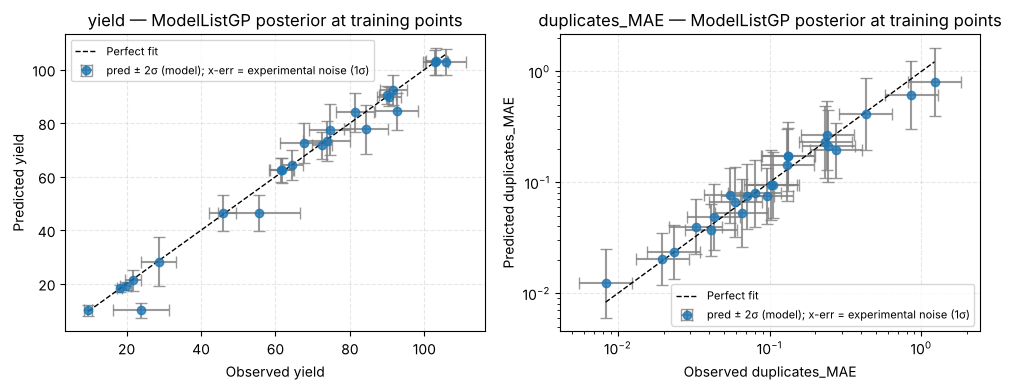

In [10]:
plot_training_fit(mlgp, 'tab:blue', 'ModelListGP posterior at training points')

#### Leave-One-Out cross-validation

For each training point, the GP is refit without it, then used to predict the held-out point. A
roughly linear trend shows the model generalises beyond memorising individual noisy observations.

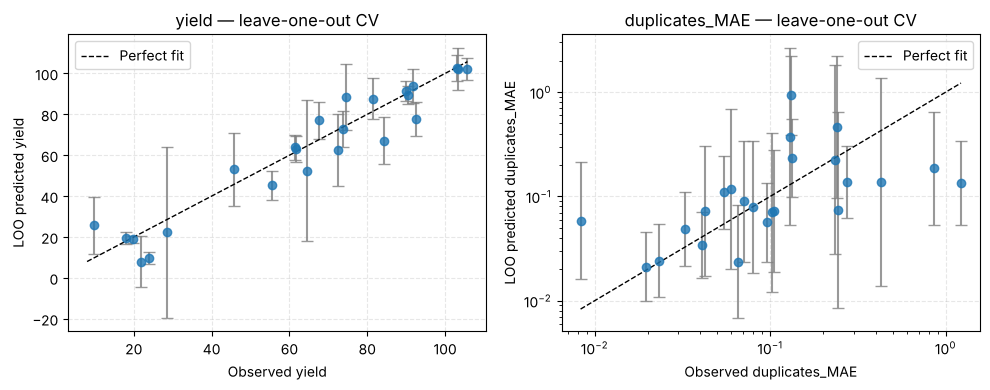

yield          : LOO R² = 0.91, 83% of held-out points within ±2σ
duplicates_MAE : LOO R² = 0.26, 83% of held-out points within ±2σ


In [11]:
def loo_predictions(train_X, train_Y, train_Yvar, output_idx):
    n = train_X.shape[0]
    loo_means = np.zeros(n)
    loo_stds  = np.zeros(n)
    y    = train_Y[:, output_idx:output_idx + 1]
    yvar = train_Yvar[:, output_idx:output_idx + 1]

    for i in range(n):
        mask = torch.ones(n, dtype=torch.bool)
        mask[i] = False
        X_tr, y_tr, yvar_tr = train_X[mask], y[mask], yvar[mask]
        X_te = train_X[i:i + 1]

        gp = SingleTaskGP(train_X=X_tr, train_Y=y_tr, train_Yvar=yvar_tr)
        mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
        fit_gpytorch_mll(mll)
        gp.eval()
        with torch.no_grad():
            post = gp.posterior(X_te)
            loo_means[i] = post.mean.item()
            loo_stds[i]  = post.variance.sqrt().item()
    return loo_means, loo_stds


# LOO in model space (raw units), then mapped back to [yield, MAE]
loo = [loo_predictions(train_X, train_Y, train_Yvar, i) for i in range(2)]
loo_mean = torch.tensor(np.column_stack([m for m, _ in loo]), dtype=dtype)
loo_std  = torch.tensor(np.column_stack([s for _, s in loo]), dtype=dtype)
pred, pred_lo, pred_hi = to_original_units((loo_mean - Y_mean) / Y_std, (loo_std / Y_std) ** 2, k=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax in enumerate(axes):
    y_obs = Y_raw[:, i]

    ax.errorbar(y_obs, pred[:, i], yerr=[pred[:, i] - pred_lo[:, i], pred_hi[:, i] - pred[:, i]],
                fmt='o', color='tab:blue', ecolor='grey', capsize=4, alpha=0.8)
    lims = [min(y_obs.min(), pred[:, i].min()), max(y_obs.max(), pred[:, i].max())]
    ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect fit')
    if i == 1:
        ax.set_xscale('log')
        ax.set_yscale('log')
    ax.set_xlabel(f'Observed {output_cols[i]}')
    ax.set_ylabel(f'LOO predicted {output_cols[i]}')
    ax.set_title(f'{output_cols[i]} — leave-one-out CV')
    ax.legend()
    ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

# Out-of-sample R² in model space, and fraction of held-out points inside ±2σ (model + experimental noise)
for i, name in enumerate(output_cols):
    resid = train_Y[:, i].numpy() - loo_mean[:, i].numpy()
    r2 = 1 - np.sum(resid ** 2) / np.sum((train_Y[:, i].numpy() - train_Y[:, i].numpy().mean()) ** 2)
    total_sd = np.sqrt(loo_std[:, i].numpy() ** 2 + train_Yvar[:, i].numpy())
    print(f"{name:<15}: LOO R² = {r2:.2f}, {np.mean(np.abs(resid / total_sd) < 2):.0%} of held-out points within ±2σ")

Note: `SingleTaskGP` standardises `train_Y`/`train_Yvar` internally by default (`outcome_transform=Standardize`),
which is why the raw (unscaled) model-space `train_Y`/`train_Yvar` can be passed directly here and
`post.mean`/`post.variance` already come back in model-space units.

## 3.2 Model B — MultiTaskGP (correlated MTGP, with known noise)

`MultiTaskGP` implements an ICM-style coregionalization: the joint covariance factorises into a data
kernel over the inputs and a learned task covariance matrix over the outputs, so it can borrow
strength across `yield` and the discrepancy when they're correlated. It uses a "stacked" data layout
(an extra task-index column in `X`) and accepts `train_Yvar`. `MultiTaskGP` takes a single likelihood
for both tasks, so it could not mix known yield noise with a learned discrepancy noise; this is why the
discrepancy noise is fixed in Section 2.2 rather than left to each model.

`rank=2` (full rank for 2 outputs) is kept from v2, so the task correlation is estimated rather than
forced to $\pm 1$.

In [12]:
def build_mtgp(train_X, train_Y, train_Yvar=None, rank=2):
    '''
    MultiTaskGP with ICM coregionalization, stacked ("long") data layout.
    Every training point is duplicated once per output, with an extra task-index
    column appended to X. rank controls the expressivity of the task covariance.
    '''
    n, d = train_X.shape
    m = train_Y.shape[1]

    X_stack = train_X.repeat(m, 1)
    task_idx = torch.cat([torch.full((n, 1), i, dtype=train_X.dtype) for i in range(m)], dim=0)
    X_aug = torch.cat([X_stack, task_idx], dim=-1)   # (n*m, d+1), task index is the last column

    Y_stack = torch.cat([train_Y[:, i:i + 1] for i in range(m)], dim=0)          # (n*m, 1)
    Yvar_stack = None
    if train_Yvar is not None:
        Yvar_stack = torch.cat([train_Yvar[:, i:i + 1] for i in range(m)], dim=0)  # (n*m, 1)

    return MultiTaskGP(
        train_X=X_aug, train_Y=Y_stack, train_Yvar=Yvar_stack,
        task_feature=-1, output_tasks=list(range(m)), rank=rank,
    )

# --------------------------------------------------------------------
# Initialize and fit model
# --------------------------------------------------------------------
mtgp = build_mtgp(train_X, train_Y_scaled, train_Yvar_scaled, rank=2)
mll_mtgp = ExactMarginalLogLikelihood(mtgp.likelihood, mtgp)
fit_gpytorch_mll(mll_mtgp)
print("MTGP (MultiTaskGP) trained (fixed observation noise per point).")

# --------------------------------------------------------------------
# Inspect the learned task covariance K_f
# --------------------------------------------------------------------
mtgp.eval()
with torch.no_grad():
    # The task-index kernel lives inside covar_module.kernels (a ProductKernel of
    # the data kernel and the task/index kernel); its covar_factor gives the
    # Cholesky-like factor of the learned inter-task covariance K_f.
    task_kernel = [k for k in mtgp.covar_module.kernels if hasattr(k, "covar_factor")][0]
    cf = task_kernel.covar_factor.detach()
    Kf = cf @ cf.T
    print(f"Learned K_f (inter-task covariance):\n{Kf.numpy().round(4)}")
    print(f"Implied correlation between yield and -log(MAE): {(Kf[0, 1] / (Kf[0, 0] * Kf[1, 1]).sqrt()).item():.2f}")

MTGP (MultiTaskGP) trained (fixed observation noise per point).
Learned K_f (inter-task covariance):
[[1.4812 1.2422]
 [1.2422 1.0799]]
Implied correlation between yield and -log(MAE): 0.98


/usr/local/lib/python3.13/dist-packages/linear_operator/utils/interpolation.py:66: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  summing_matrix = torch.sparse_coo_tensor(


### Training quality check

#### Posterior mean vs observed values

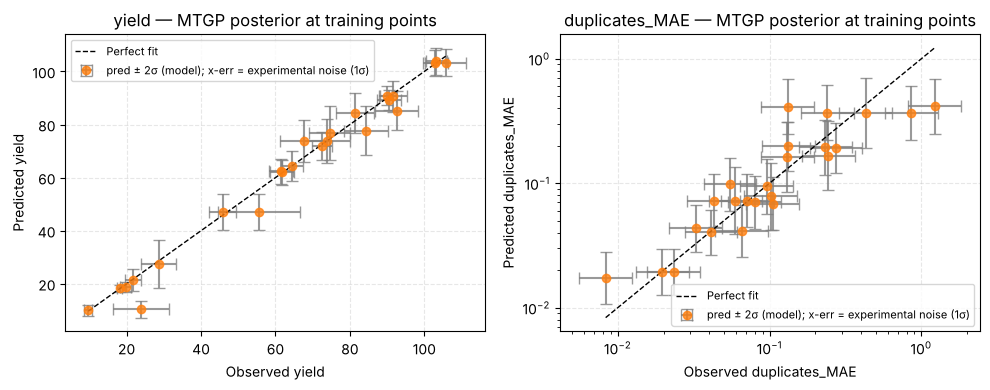

In [13]:
plot_training_fit(mtgp, 'tab:orange', 'MTGP posterior at training points')

## 3.3 Model C — Random Forest with Bootstrap Uncertainty + Known Noise

Unchanged from v2: one RF per output, inverse-variance sample weights at fit time, and the mean noise
variance of each output added as a noise floor at prediction time (see v2 for the full discussion).
With `DISC_NOISE = 'pooled'` the discrepancy noise is the same for every point, so its sample weights are
uniform and only the noise floor uses it.

In [14]:
class RFPosterior(Posterior):
    '''
    Minimal BoTorch-compatible posterior backed by RF tree-variance.

    _mean:  (batch, q, m)
    _variance: (batch, q, m)  — diagonal only, trees assumed independent per output
    '''
    def __init__(self, mean: Tensor, variance: Tensor):
        super().__init__()
        self._mean = mean
        self._variance = variance

    @property
    def device(self) -> torch.device:
        return self._mean.device

    @property
    def dtype(self) -> torch.dtype:
        return self._mean.dtype

    @property
    def mean(self) -> Tensor:
        return self._mean

    @property
    def variance(self) -> Tensor:
        return self._variance

    @property
    def base_sample_shape(self) -> torch.Size:
        # Shape of the "event" dimension — one independent normal per output per candidate
        return torch.Size([self._mean.shape[-2], self._mean.shape[-1]])  # (q, m)

    @property
    def batch_range(self) -> tuple[int, int]:
        return (0, 0)

    @property
    def batch_shape(self) -> torch.Size:
        # Everything in _mean except the last two dims (q, m) is batch
        return self._mean.shape[:-2]

    def _extended_shape(self, sample_shape: torch.Size = torch.Size()) -> torch.Size:
        return sample_shape + self._mean.shape

    def rsample_from_base_samples(
        self, sample_shape: torch.Size, base_samples: torch.Tensor
    ) -> torch.Tensor:
        std = self._variance.clamp(min=1e-9).sqrt()
        # base_samples: (*sample_shape, *batch, q, m)
        # mean/std:     (*batch, q, m)
        # Align by expanding mean/std to match all leading dims of base_samples
        extra_dims = base_samples.dim() - self._mean.dim()
        mean = self._mean
        for _ in range(extra_dims):
            mean = mean.unsqueeze(0)
            std = std.unsqueeze(0)
        return mean + base_samples * std

    def rsample(self, sample_shape: torch.Size = torch.Size()) -> Tensor:
        '''
        Draw reparameterized samples: mu + eps * sigma, eps ~ N(0,1).
        Returns shape (*sample_shape, *batch_shape, q, m).
        This is what Monte Carlo acquisition functions (qNEHVI) integrate over.
        '''
        std = self._variance.clamp(min=1e-9).sqrt()
        eps = torch.randn(
            *sample_shape, *self._mean.shape,
            dtype=self._mean.dtype, device=self._mean.device
        )
        return self._mean + eps * std


class RandomForestModel(Model):
    '''
    BoTorch Model wrapper around one sklearn RandomForestRegressor per output.
    Uncertainty = tree-ensemble variance (epistemic) + known-noise floor (aleatoric).
    '''
    def __init__(self, train_X: Tensor, train_Y: Tensor, train_Yvar: Tensor = None, **rf_kwargs):
        super().__init__()
        self._num_outputs = train_Y.shape[-1]
        X_np = train_X.detach().cpu().numpy()
        Y_np = train_Y.detach().cpu().numpy()

        self.rfs = []
        self._noise_floor = np.zeros(self._num_outputs)
        for i in range(self._num_outputs):
            rf = RandomForestRegressor(
                n_estimators=rf_kwargs.get('n_estimators', 500),
                max_depth=rf_kwargs.get('max_depth', None),
                random_state=RSEED,
            )
            sample_weight = None
            if train_Yvar is not None:
                var_i = train_Yvar[:, i].detach().cpu().numpy()
                sample_weight = 1.0 / np.clip(var_i, 1e-8, None)   # inverse-variance weighting
                sample_weight = sample_weight / sample_weight.mean()  # normalise for stability
                self._noise_floor[i] = var_i.mean()                # aleatoric floor for unseen X
            rf.fit(X_np, Y_np[:, i], sample_weight=sample_weight)
            self.rfs.append(rf)

        self._dtype = train_X.dtype
        self._device = train_X.device

    @property
    def num_outputs(self) -> int:
        return self._num_outputs

    def posterior(self, X: Tensor, **kwargs) -> RFPosterior:
        '''
        Compute tree-ensemble mean/variance + noise floor.
        X shape: (..., q, d)  — arbitrary batch dimensions + q candidates
        Returns posterior with mean/variance shape (..., q, m).
        '''
        batch_shape = X.shape[:-2]
        q, d = X.shape[-2], X.shape[-1]
        X_flat = X.reshape(-1, d).detach().cpu().numpy()  # (batch*q, d)

        means, varis = [], []
        for i, rf in enumerate(self.rfs):
            tree_preds = np.stack([tree.predict(X_flat) for tree in rf.estimators_], axis=0)  # (n_trees, batch*q)
            means.append(tree_preds.mean(axis=0))
            varis.append(tree_preds.var(axis=0) + self._noise_floor[i])
        mean_np = np.stack(means, axis=-1)   # (batch*q, m)
        var_np  = np.stack(varis, axis=-1)   # (batch*q, m)

        m = self._num_outputs
        mean = torch.tensor(mean_np, dtype=self._dtype, device=self._device).reshape(*batch_shape, q, m)
        var  = torch.tensor(var_np,  dtype=self._dtype, device=self._device).reshape(*batch_shape, q, m)

        return RFPosterior(mean, var)

# --------------------------------------------------------------------
# Initialize and fit model
# --------------------------------------------------------------------
rf_model = RandomForestModel(train_X, train_Y_scaled, train_Yvar_scaled, n_estimators=500)
print("RF model trained (per-output, inverse-variance sample weighting + noise floor).")

# Sanity check
test_post = rf_model.posterior(train_X[:3].unsqueeze(0))  # batch (1, 3, d)
print(f"RF posterior mean shape: {test_post.mean.shape}")  # (1, 3, 2)

RF model trained (per-output, inverse-variance sample weighting + noise floor).
RF posterior mean shape: torch.Size([1, 3, 2])


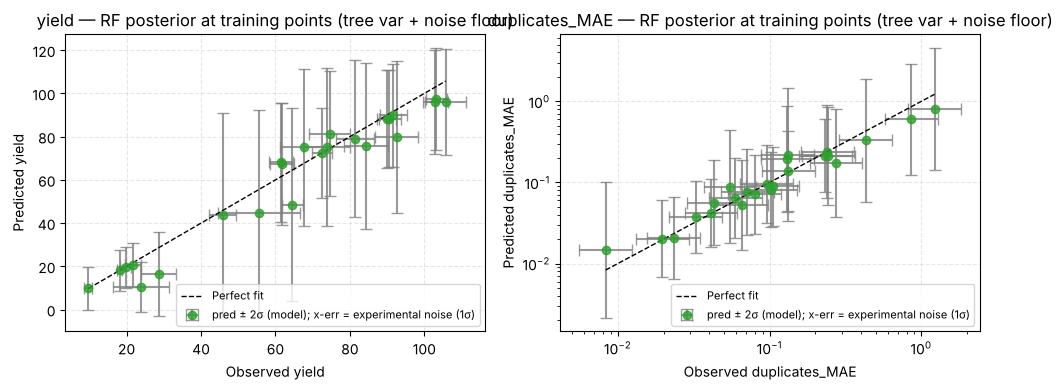

In [15]:
plot_training_fit(rf_model, 'tab:green', 'RF posterior at training points (tree var + noise floor)')

## 4. Batch BO — qLogNEHVI

Same acquisition set-up as v2. `qLogNEHVI` maximises the expected hypervolume improvement of
(yield, $-\log\mathrm{MAE}$) over the reference point (yield = 0 %, MAE = `MAE_REF`), and it accounts for
the noise of both objectives through the `train_Yvar` given to the GPs. The RF uses the same
Pareto-spread selection as in v2.

**One change from v2: the batch is built sequentially** (`optimize_acqf(..., sequential=True)`):
candidate 1 is optimised first, then candidate 2 given candidate 1, and so on. Here, the two objectives
pull in the same direction (both are best at low CHOL), so one or two candidates already capture almost
all of the expected improvement. When the 3 candidates are optimised jointly, a candidate that adds
nothing has zero gradient and is left wherever its random start was: with the MTGP, one of the 3
suggestions added practically nothing in 4 out of 5 random seeds (e.g. a CHOL = 8 experiment predicted
at ~18 % yield). The sequential batch makes every candidate the best *remaining* experiment, and gave a
higher expected hypervolume improvement for the whole batch in 9 of the 10 seed/model combinations tested.
The printed values are therefore one per suggestion: the (log) improvement each one adds on top of the
previous ones.

In [16]:
BATCH_SIZE = 3       # number of new experiments to suggest
NUM_RESTARTS = 10    # random restarts for acq optimisation
RAW_SAMPLES = 512    # initial MC samples for candidate seeding
MC_SAMPLES = 128     # samples for qNEHVI integration


def suggest_experiments(model, train_X, train_Y, ref_point_tensor, label="model"):
    '''
    Run one round of batch BO with qLogNEHVI.
    Returns suggested candidates in the *original* (unnormalised) input space.
    '''
    with manual_seed(RSEED):

        # --------------------------------------------------------------------
        # Compute acquisition function
        # --------------------------------------------------------------------
        acq = qLogNoisyExpectedHypervolumeImprovement(
            model=model,
            ref_point=ref_point_tensor,
            X_baseline=train_X,
            sampler=SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES])),
        )

        # --------------------------------------------------------------------
        # Optimize the objective and suggest q experiments
        # --------------------------------------------------------------------
        # sequential=True: greedy, one candidate at a time given the previous ones (see markdown above)
        candidates_norm, acq_value = optimize_acqf(
            acq_function=acq,
            bounds=unit_bounds,
            q=BATCH_SIZE,
            num_restarts=NUM_RESTARTS,
            raw_samples=RAW_SAMPLES,
            options={"batch_limit": 5, "maxiter": 200},
            sequential=True,
        )

    # --------------------------------------------------------------------
    # Denormalise candidates back to original input ranges
    # --------------------------------------------------------------------
    candidates_orig = unnormalize(candidates_norm.detach(), bounds=X_bounds)

    print(f"\n{'='*55}")
    print(f"  {label} — suggested experiments")
    print(f"{'='*55}")
    df_sugg = pd.DataFrame(candidates_orig.numpy(), columns=input_cols)
    df_sugg.index = [f"Suggestion_{i+1}" for i in range(BATCH_SIZE)]
    print(df_sugg.round(4))
    # One value per candidate: its own improvement given the candidates before it
    print(f"  qLogNEHVI per suggestion: {acq_value.numpy().round(4)}")
    return candidates_orig, df_sugg


def suggest_experiments_rf(rf_model, X_bounds, n_candidates=10000, batch_size=3):
    rng = check_random_state(RSEED)
    d = X_bounds.shape[1]

    # 1. Sample candidates uniformly in [0,1]^d (normalised space)
    X_cands_norm = rng.uniform(0, 1, size=(n_candidates, d))

    # 2. Predicted mean of each output (tree average, scaled model space)
    post = rf_model.posterior(torch.tensor(X_cands_norm, dtype=dtype))
    Y_cands_mean = post.mean.numpy()   # (n_candidates, 2)

    # 3. Find Pareto-non-dominated candidates (based on mean predictions)
    pareto_mask = is_non_dominated(torch.tensor(Y_cands_mean, dtype=dtype)).numpy()

    X_pareto      = X_cands_norm[pareto_mask]
    Y_pareto_mean = Y_cands_mean[pareto_mask]
    print(f"  Pareto front size among candidates: {X_pareto.shape[0]}")

    # 4. Greedily select batch_size points with max spread in output space
    selected  = []
    remaining = list(range(len(X_pareto)))

    first = np.argmax(Y_pareto_mean[:, 0])
    selected.append(first)
    remaining.remove(first)

    while len(selected) < min(batch_size, len(X_pareto)):
        dists = np.array([
            min(np.linalg.norm(Y_pareto_mean[i] - Y_pareto_mean[s]) for s in selected)
            for i in remaining
        ])
        next_idx = remaining[np.argmax(dists)]
        selected.append(next_idx)
        remaining.remove(next_idx)

    # 5. Unnormalise to the original input space
    X_sel_orig = unnormalize(
        torch.tensor(X_pareto[selected], dtype=dtype), bounds=X_bounds
    )

    print(f"\n{'='*55}")
    print(f"  RandomForest — suggested experiments (original space)")
    print(f"{'='*55}")
    df_sugg = pd.DataFrame(X_sel_orig.numpy(), columns=input_cols)
    df_sugg.index = [f"Suggestion_{i+1}" for i in range(len(selected))]
    print(df_sugg.round(4))

    return X_sel_orig, df_sugg

In [17]:
# --- Model A: ModelListGP ---
cands_mlgp, df_mlgp = suggest_experiments(mlgp, train_X, train_Y_scaled, ref_point_scaled, label="ModelListGP (independent GPs)")


  ModelListGP (independent GPs) — suggested experiments
              thickness   density  porosity  CHOL_input
Suggestion_1     0.3200  290.5619   64.0524       0.784
Suggestion_2     7.6118  289.2841   60.1000       0.784
Suggestion_3     0.3200  263.1846   60.1000       0.784
  qLogNEHVI per suggestion: [-0.3717 -0.8097 -1.6638]


In [18]:
# --- Model B: MultiTaskGP ---
cands_mtgp, df_mtgp = suggest_experiments(mtgp, train_X, train_Y_scaled, ref_point_scaled, label="MultiTaskGP (MTGP)")


  MultiTaskGP (MTGP) — suggested experiments
              thickness  density  porosity  CHOL_input
Suggestion_1     0.3200    317.0      60.1       0.784
Suggestion_2    10.0000    317.0      60.1       0.784
Suggestion_3     2.8602     60.0      60.1       0.784
  qLogNEHVI per suggestion: [-0.9449 -0.8851 -1.4987]


In [19]:
#--- Model C: RandomForest ---

cands_rf, df_rf = suggest_experiments_rf(rf_model, X_bounds)

  Pareto front size among candidates: 3

  RandomForest — suggested experiments (original space)
              thickness   density  porosity  CHOL_input
Suggestion_1     5.6811  247.7917   61.2388      0.8648
Suggestion_2     0.4765  212.0589   60.4405      0.7927
Suggestion_3     3.0201  303.9270   69.7645      0.8100


## 5. Compare Suggestions in Output Space

Each model's predicted outcome at its own suggestions (±1σ), on top of the observed data and its
Pareto front. The best region is the **bottom right**: high yield, low discrepancy.

Observed Pareto front:
   thickness  density  porosity  CHOL_input    yield  duplicates_MAE
0      4.070      317      65.0       0.790  105.740        0.023266
2      3.094      279      60.1       0.784  103.215        0.008305


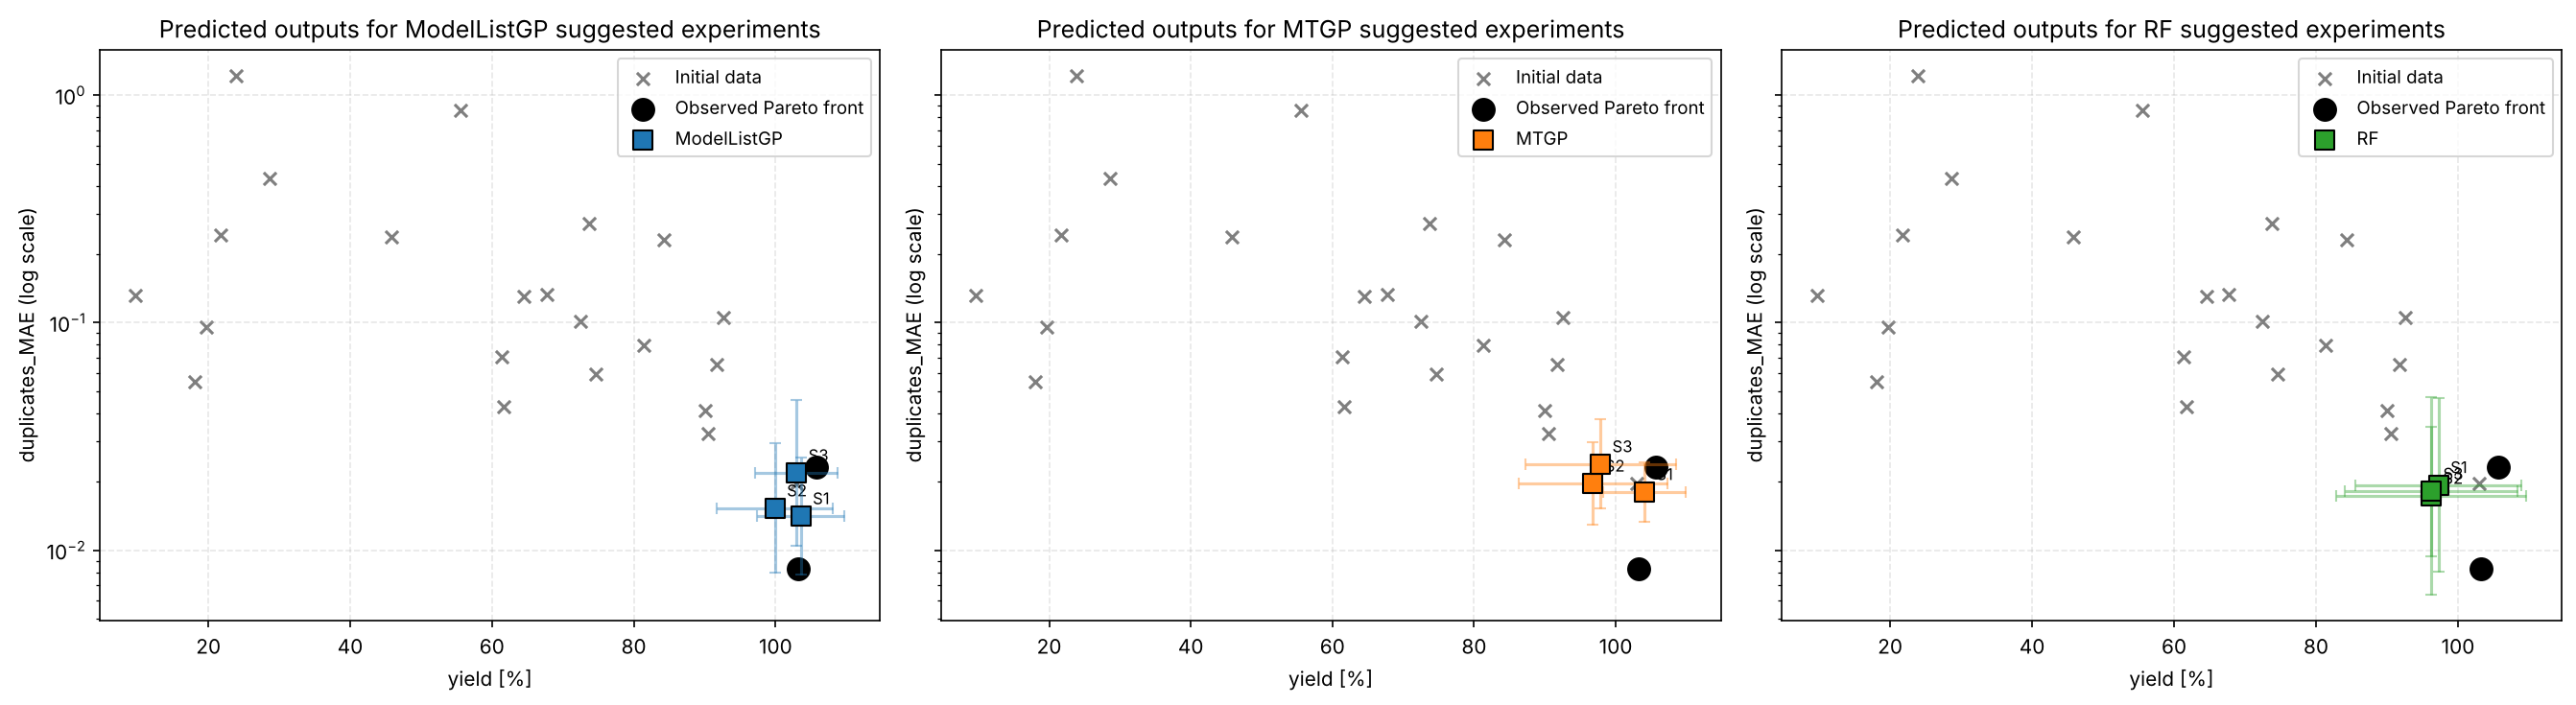

In [20]:
def predict_outputs(model, candidates_orig):
    '''Predicted [yield, MAE] at the suggested inputs, with the 1σ band, in original units.'''
    model.eval()
    with torch.no_grad():
        post = model.posterior(normalize(candidates_orig, bounds=X_bounds))
        return to_original_units(post.mean, post.variance, k=1)


models = {'ModelListGP': (mlgp, cands_mlgp, df_mlgp, 'tab:blue'),
          'MTGP':        (mtgp, cands_mtgp, df_mtgp, 'tab:orange'),
          'RF':          (rf_model, cands_rf, df_rf, 'tab:green')}
preds = {label: predict_outputs(model, cands) for label, (model, cands, _, _) in models.items()}

# Pareto front of observed data (same set in model space and in (yield, MAE))
pareto_mask = is_non_dominated(train_Y)
pareto_Y = Y_raw[pareto_mask.numpy()]
print("Observed Pareto front:")
print(df.loc[pareto_mask.numpy(), input_cols + output_cols])

fig, ax = plt.subplots(1, 3, figsize=(18, 5), dpi=150, sharey=True)

for k, (label, (_, _, _, color)) in enumerate(models.items()):
    centre, lower, upper = preds[label]
    ax[k].scatter(Y_raw[:, 0], Y_raw[:, 1], c='black', marker='x', s=40, alpha=0.5, label='Initial data')
    ax[k].scatter(pareto_Y[:, 0], pareto_Y[:, 1], c='black', marker='o', s=120, zorder=5, label='Observed Pareto front')

    ax[k].scatter(centre[:, 0], centre[:, 1], marker='s', c=color, s=100, edgecolors='black', zorder=10, label=label)
    ax[k].errorbar(centre[:, 0], centre[:, 1],
                   xerr=[centre[:, 0] - lower[:, 0], upper[:, 0] - centre[:, 0]],
                   yerr=[centre[:, 1] - lower[:, 1], upper[:, 1] - centre[:, 1]],
                   fmt='none', ecolor=color, alpha=0.4, capsize=3, capthick=1, zorder=9)
    for j in range(len(centre)):
        ax[k].annotate(f"S{j + 1}", (centre[j, 0], centre[j, 1]), textcoords='offset points', xytext=(6, 6), fontsize=8)

    ax[k].set_yscale('log')
    ax[k].legend(fontsize=9)
    ax[k].set_xlabel('yield [%]')
    ax[k].set_ylabel('duplicates_MAE (log scale)')
    ax[k].set_title(f'Predicted outputs for {label} suggested experiments')
    ax[k].grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

## 6. Summary Table

Predictions in original units: yield as mean ± 1σ; the MAE as the posterior median with its 1σ range
(`MAE_low` – `MAE_high`). `closest_material` is the tested material with the nearest properties
(thickness, density, porosity in normalised units).

In [21]:
mat_props = (full_inputs_df.drop_duplicates('material')
             .set_index('material')[['thickness', 'density', 'porosity']])
mat_props_norm = normalize(torch.tensor(mat_props.values, dtype=dtype), bounds=X_bounds[:, :3])


def summary_df(df_sugg, cands, pred, model_name):
    centre, lower, upper = pred
    d = df_sugg.copy()
    d.insert(0, 'model', model_name)
    dist = torch.cdist(normalize(cands, bounds=X_bounds)[:, :3], mat_props_norm)
    d['closest_material'] = mat_props.index[dist.argmin(dim=1).numpy()]
    d['pred_yield']        = centre[:, 0].round(2)
    d['pred_uncert_yield'] = (upper[:, 0] - centre[:, 0]).round(2)
    d['pred_MAE']          = centre[:, 1].round(4)
    d['MAE_low']           = lower[:, 1].round(4)
    d['MAE_high']          = upper[:, 1].round(4)
    return d


summary = pd.concat([summary_df(df_sugg, cands, preds[label], label)
                     for label, (_, cands, df_sugg, _) in models.items()])
print(summary.to_string())

                    model  thickness     density   porosity  CHOL_input closest_material  pred_yield  pred_uncert_yield  pred_MAE  MAE_low  MAE_high
Suggestion_1  ModelListGP   0.320000  290.561859  64.052410    0.784000           Poplar      103.55               6.17    0.0141   0.0078    0.0255
Suggestion_2  ModelListGP   7.611815  289.284119  60.100000    0.784000            Kapok       99.91               8.17    0.0153   0.0079    0.0295
Suggestion_3  ModelListGP   0.320000  263.184616  60.100000    0.784000           Poplar      102.94               5.82    0.0219   0.0104    0.0458
Suggestion_1         MTGP   0.320000  317.000000  60.100000    0.784000           Poplar      104.03               5.80    0.0180   0.0133    0.0244
Suggestion_2         MTGP  10.000000  317.000000  60.100000    0.784000         Milkweed       96.76              10.50    0.0196   0.0129    0.0299
Suggestion_3         MTGP   2.860187   60.000000  60.100000    0.784000           Poplar       97.82      

In [22]:
# Raw original input values
inputs_df[['material', 'thickness', 'density', 'porosity']].drop_duplicates(subset='material').reset_index(drop=True)

,material,thickness,density,porosity
0,Poplar,3.094,279,60.1
1,Kapok,4.050,312,65.0
2,Milkweed,4.070,317,65.0
3,Viscose,0.320,60,84.0
4,Porous_PET,0.345,80,84.0
5,Fluffy_PET,10.000,100,87.0


# Visualizing learned CHOL dependency

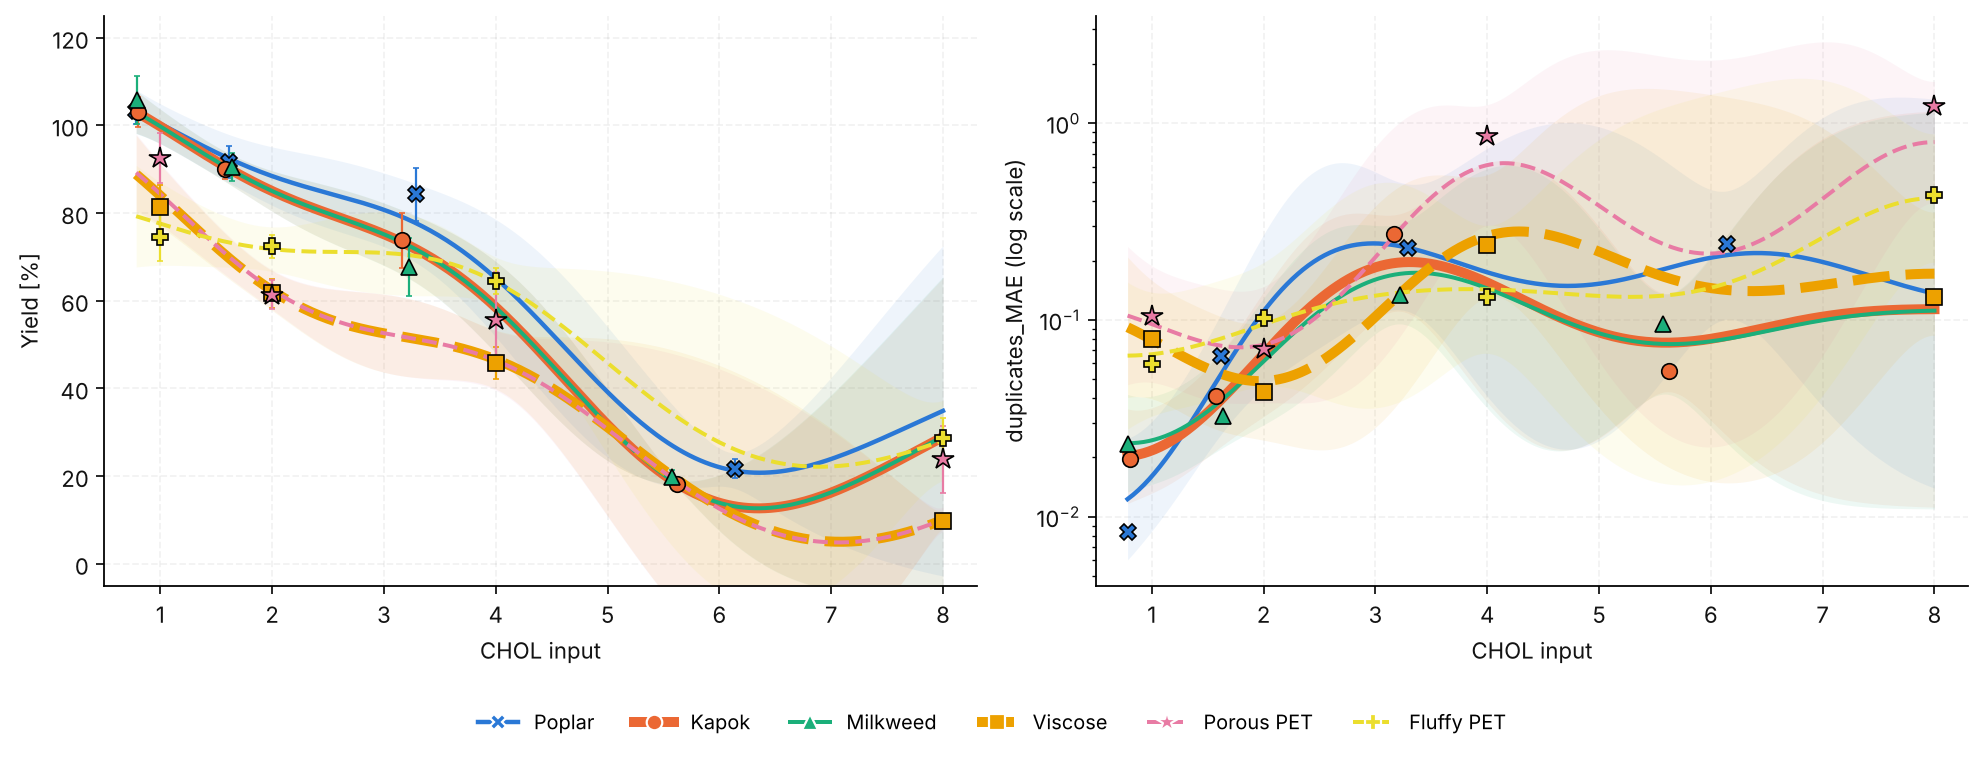

In [23]:
# ------------------------------------------------------------------------------
# ModelListGP beliefs along CHOL: one curve per material, each with a ±2σ band.
# Yield on the left, duplicate discrepancy (log scale) on the right.
# ------------------------------------------------------------------------------
from matplotlib.lines import Line2D

SURF, INK2 = "#ffffff", "#131313"

# One color + marker + line width per material
mat_style = {
    'Poplar':     ("#2a78d6", "X", 2.0, '-'),
    'Kapok':      ("#eb6834", "o", 4.5, '-'),
    'Milkweed':   ("#1baf7a", "^", 1.8, '-'),
    'Viscose':    ("#eda100", "s", 4.5, '--'),
    'Porous_PET': ("#e87ba4", "*", 1.8, '--'),
    'Fluffy_PET': ("#ebde2e", "P", 1.8, '--'),
}

chol_grid = np.linspace(full_inputs_df['CHOL_input'].min(), full_inputs_df['CHOL_input'].max(), 300)

def gp_along_chol(model, props):
    '''Posterior centre and ±2σ band (original units) along the CHOL grid for fixed material properties.'''
    X_grid = torch.tensor([list(props) + [c] for c in chol_grid], dtype=dtype)
    model.eval()
    with torch.no_grad():
        post = model.posterior(normalize(X_grid, bounds=X_bounds))
        return to_original_units(post.mean, post.variance, k=2)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0), dpi=160, facecolor=SURF)
ylabels = ["Yield [%]", "duplicates_MAE (log scale)"]
observed = [(full_outputs_df[output_1], full_outputs_df[output_1 + '_SD']),
            (full_outputs_df[output_2], None)]

for i, ax in enumerate(axes):
    ax.set_facecolor(SURF)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.grid(True, color='black', alpha=0.05, linestyle='--', linewidth=0.8)
    ax.set_axisbelow(True)

    # Each real material: GP curve + band, measured points (with reported SD for the yield)
    for mat, (col, mk, lw, ls) in mat_style.items():
        centre, lower, upper = gp_along_chol(mlgp, mat_props.loc[mat].values)
        ax.fill_between(chol_grid, lower[:, i], upper[:, i], color=col, alpha=0.08, linewidth=0)
        ax.plot(chol_grid, centre[:, i], color=col, lw=lw, ls=ls)
        mask = full_inputs_df['material'] == mat
        values, sds = observed[i]
        ax.errorbar(full_inputs_df.loc[mask, 'CHOL_input'], values[mask],
                    yerr=None if sds is None else sds[mask],
                    fmt=mk, ms=10 if mk == "*" else 7, color=col, mec='black', mew=0.75,
                    ecolor=col, elinewidth=1, capsize=1.5, zorder=5)

    ax.set_xlabel("CHOL input", color=INK2)
    ax.set_ylabel(ylabels[i], color=INK2)
    ax.tick_params(colors=INK2)
    ax.set_xlim(0.5, 8.3)

axes[0].set_ylim(-5, 125)
axes[1].set_yscale('log')

handles = [Line2D([0], [0], color=col, lw=lw, linestyle=ls, marker=mk, ms=10 if mk == "*" else 7, mec=SURF, label=mat.replace('_', ' '))
           for mat, (col, mk, lw, ls) in mat_style.items()]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.0001))
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()

# 7. Results discussion

**The two objectives mostly agree.** Both are driven by CHOL: the yield falls as CHOL increases
(Spearman $\rho = -0.91$) while the discrepancy grows with it ($\rho = +0.75$). The observed Pareto front
has only two points, both at the lowest CHOL: Milkweed (yield 105.7 %, MAE 0.023) and Poplar
(103.2 %, MAE 0.008). This is very different from yield vs biomass productivity in v2, where
productivity peaks around CHOL ≈ 3 and creates a real trade-off.

**The discrepancy is a much noisier and less predictable objective than the yield.**
- Each MAE is the mean of only 3 absolute differences between 2 replicates, so it carries about 40 %
  relative uncertainty (pooled estimate, ×/÷ 1.49), against about 6 % for the yield. A GP left to learn this
  noise settles on about 10 %, i.e. it would treat the discrepancies as far more precise than they are.
- Leave-one-out $R^2$ is 0.91 for the yield but only 0.26 for $-\log(\mathrm{MAE})$. The model captures the
  CHOL trend (low CHOL → reproducible), not the material-specific behaviour at high CHOL: Viscose and
  Porous PET have almost identical properties (thickness 0.32 vs 0.345, density 60 vs 80, porosity 84 %
  for both), yet their MAE at CHOL 4 and 8 differs by a factor 4–9 (0.24 / 0.13 vs 0.86 / 1.22). Either the
  discrepancy depends on something that thickness, density and porosity do not describe, or those runs
  were simply poorly reproducible; with two replicates the two cannot be told apart.
- The MTGP learns a task correlation of 0.98, and ICM shares one set of input lengthscales across both
  tasks: it effectively treats $-\log(\mathrm{MAE})$ as a rescaled copy of the yield, so its discrepancy
  predictions are pulled towards the yield trend (compare its training fit with the ModelListGP's).

**Suggestions.** Every suggestion sits at, or within 0.1 of, the lowest tested CHOL (0.784), with dense,
low-porosity materials, i.e. the natural-fibre corner of the property space (Poplar / Kapok / Milkweed:
density 279–317, porosity 60–65 %):

| model | proposed materials, all at CHOL ≈ 0.78 |
|---|---|
| ModelListGP | density 263–291, porosity 60–64 %, thickness at the extremes: 0.32 (twice) and 7.6 |
| MTGP | porosity 60.1 % with density 317 and thickness 0.32 or 10; plus a low-density (60) material of thickness 2.9 |
| RF | Poplar / Kapok-like materials (thickness 0.5–5.7, density 212–304, porosity 60–70 %) |

- The GP suggestions are mostly *exploration*. Thickness has only been varied among the light, porous
  synthetics (Viscose, PET), never among the dense, low-porosity fibres, so a thin or thick dense material at low CHOL is
  where the predictions are most uncertain. Their predicted means (yield 97–104 %, MAE 0.014–0.024) are at
  best level with the current Pareto points, by margins far smaller than the uncertainties; the expected
  improvement comes mainly from the uncertainty.
- The RF cannot extrapolate beyond the tested materials, so it proposes interpolations of Poplar and Kapok.
- The MTGP's third suggestion pairs a low density (60) with a low porosity (60 %). The optimiser treats
  density and porosity as independent, but in real materials they are linked, so such a combination may not exist.
- Across 5 random seeds the exact numbers change, but the pattern (lowest CHOL, porosity near 60 %, mostly
  high density, extreme thicknesses for the GPs) is stable. It is also largely unchanged with the other two
  `DISC_NOISE` options, which mainly make the models more confident (and add some suggestions at 70–81 % porosity).

**What this means in practice**
1. Maximising yield and minimising discrepancy both point to the lowest CHOL. That is also where biomass
   productivity is lowest in the dataset (0.42–0.52, against 1.49 at CHOL ≈ 3.3). If productivity still
   matters, it should stay in the loop as a third objective or as a constraint; otherwise the loop will keep
   proposing low-CHOL runs.
2. The suggested optimum lies on the lower edge of the tested CHOL range (0.784); the models cannot say
   what happens below it.
3. With about 40 % uncertainty on each MAE, two conditions are only distinguishable (at 2σ) when their
   discrepancies differ by roughly a factor of 3. More replicates or more sampling times per CHOL phase would
   sharpen this objective more than additional BO iterations.